# This is a tutorial for doing the pileup analysis

## Imports

In [2]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import src.analysis as an
import src.dataset as ds
import torch
from scipy.stats import norm
from utility.double_beta_spectrum import pdf_ratio2b
import utility.functions as fn
BASE = "../"
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Choose analysis parameters

In [3]:
meas_name = "000813_20230628T161508"
channel = 5
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100) #number of sigma corresponding to the desired acceptance
signal_amp = 11.182*1e-3 #expected amplitude of the signal at the Q-value
#define the time and ratio grid for the analysis
t_min, t_max, N_t = 0, 8e-4, 100
r_min, r_max, N_r = 0., .5, 100
#get the corresponding ratio distribution 
ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
ratio_distribution /= np.mean(ratio_distribution)

window_size = 800 #size of the window used for the analysis, should be the same as the one used for the NPS computation
n_trials=100 #number of trials for the optimization of the filters

## Load the meanpulse and Noise power spectrum
if they are not already compute, look build_meanpulses.py and build_NPS.py to compute them

In [ ]:
#load the meanpulse
meanpulse = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_mean.npy")
if len(meanpulse) > window_size:
    meanpulse = meanpulse[np.argmax(meanpulse) - window_size//2 : np.argmax(meanpulse) + window_size//2]
#load the NPS
nps = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
nps *= (8. / 3.)  # Adjust for Hann window effect

In [4]:
nps = np.fromfile(f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_spec.bin")
nps *= (8. / 3.)  # Adjust for Hann window effect
nps *= 1e-12  # Adjust to from nV to V
meanpulse = np.fromfile(f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_edmean.bin")


In [5]:
rawdata_path = f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin"
dataset = ds.CachedBinaryDataset(rawdata_path, window_size,np.arange(0,20000)*window_size)
std= dataset.data.std(dim=1)
nps = an.create_NPS(
    dataset,
    rms_thr=0.00023,
    window_fct = np.hanning,
    batch_size = 2048
)

## Compute the optimal filter

In [6]:
S, w, H_unit = an.compute_H(meanpulse, nps, np.hanning,sampling_rate=2000)

In [7]:
sigma_analytic = np.sqrt(
    np.sum(np.abs(H_unit)**2 * nps)
) / window_size 
print(f"Analytic sigma: {sigma_analytic*910   :.4f} mV")
print(f"SNR: {signal_amp / sigma_analytic:.2f}")

Analytic sigma: 0.0944 mV
SNR: 107.74


## Convert the relevant arrays to torch tensors and move them to the appropriate device (CPU or GPU)

In [8]:
S_torch = torch.tensor(S, dtype=torch.cfloat, device=device)
H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat, device=device)
w_torch = torch.tensor(w, dtype=torch.cfloat, device=device)
nps_torch = torch.tensor(nps, dtype=torch.cfloat, device=device)
signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32, device=device)
t_torch = torch.linspace(t_min, t_max, N_t, dtype=torch.cfloat, device=device)
r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat, device=device)
ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat, device=device)

## Optimize the filters for minimal misidentification rate (J_value)

In [18]:
f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, 
                                                       signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma,
                                                       n_trials=100, use_interp = True, verbose=True)

f1_t = torch.tensor(f1_opt, dtype=torch.float32, device=device)
f2_t = torch.tensor(f2_opt, dtype=torch.float32, device=device)

Step 0: J = 0.884199
Step 10: J = 0.817388
Step 20: J = 0.727922
Step 30: J = 0.636196
Step 40: J = 0.562896
Step 50: J = 0.511659
Step 60: J = 0.476375
Step 70: J = 0.450985
Step 80: J = 0.431674
Step 90: J = 0.416254
Final: J = 0.404655


## Save the results

In [ ]:
np.save(f"{BASE}/outputs/training_Js/channel_{channel}/J_{int(acceptance * 100):d}", np.array(J_values))
np.save(f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance * 100):d}",np.array([f1_opt, f2_opt]))

# BI estimation
A proxi for the BI can be optained from the Misidentification rate (J_value) 

In [10]:
BI_estimate = J_values[-1] * fn.K #Here K is a constant that depends on crystal size, Mo-2b2n decay rate, maximum delay studied,...
BI_estimate

7.755814293798295e-05

# Compute the Background Index using injected pulses
If enough statistics is available, the BI can be computed directly from the injected pulse datasets, by applying the optimized filters and counting the number of misidentified pileup events.

## Load the dataset
path_pos_single and path_pos_pileup are the paths to the position files for the single pulse and pileup datasets, respectively. They contain the relevent informations for the injection (position in the raw file to inject pulse , amplitudes, delay, smearing,...). Those data are created by montecarlo from IJClab code.

In [536]:
rawdata_path = f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin"
position_file ='/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected_new/channel5/pup_n1-d0_000813_20230628T161508_005_000_stdcut.pos'
pos_single = np.loadtxt(position_file, ndmin = 2)
dataset = ds.CachedBinaryDataset(rawdata_path, window_size,np.arange(0,20000)*window_size)
std= dataset.data.std(dim=1)
position = dataset.positions[std<0.00023]
pos_single[:,0] = position[:len(pos_single)]*4
mean_amp = np.mean(pos_single[:,1])
pos_single[:,1] = pos_single[:,1]/mean_amp*signal_amp
print(np.mean(pos_single[:,1]))
pos_pileup = np.loadtxt('/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected_new/channel5/pup_n1-d8_000813_20230628T161508_005_000_stdcut.pos')
pos_pileup[:,0] = position[:len(pos_pileup)]*4
pos_pileup[:,1] = pos_pileup[:,1]/mean_amp*signal_amp
pos_pileup[:, 2] = pos_pileup[:,2]/mean_amp*signal_amp
np.savetxt("/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_pos_single.pos", pos_single)
np.savetxt("/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_pos_pileup.pos", pos_pileup)

0.011182000000000001


In [11]:
#load the pulse to be injected
# meanpulse_inj = np.fromfile(f"{BASE}/outputs/meanpulses_build/pos_pulse_channel{channel}.bin", dtype=np.float32)
meanpulse_inj = np.fromfile(f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_edmean.bin")
#load the single pulse dataset
# dataset_single_name = "pup_n1-d0_000813_20230628T161508"
# file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
#                                                   specific_subdir="RUN9_pulse_injected_new/")
# data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, window_size,
#                                                    pulse=meanpulse_inj,
#                                                    n_windows=15999, win_shift=0)
# #load the pileup pulse dataset
# dataset_pileup_name = "pup_n1-d8_000813_20230628T161508"
# file_path_pileup, path_pos_pileup = ds.find_files(meas_name, dataset_pileup_name, channel,
#                                                   specific_subdir="RUN9_pulse_injected_new/")
# data_pileup = ds.CachedBinaryDataset_withgenerated(file_path_pileup, path_pos_pileup, window_size,
#                                                    pulse=meanpulse_inj,
#                                                    n_windows=15999, win_shift=0)
rawdata_path = f"/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin"
path_pos_single ="/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_pos_single.pos"
pos_file = np.loadtxt(path_pos_single)
print(np.mean(pos_file[:, 1]))
data_single = ds.CachedBinaryDataset_withgenerated(rawdata_path, path_pos_single, window_size, pulse=meanpulse_inj, n_windows=15999, win_shift=0)
path_pos_pileup ="/local/home/mp274748/Documents/data/RUN14/000204_20260405T115934_071_000.bin_pos_pileup.pos"
data_pileup = ds.CachedBinaryDataset_withgenerated(rawdata_path, path_pos_pileup, window_size, pulse=meanpulse_inj, n_windows=15999, win_shift=0)


0.011182000000000001
(15999, 3)
(15999, 7)


In [30]:
window = torch.tensor(np.hanning(window_size))
data = dataset.data - dataset.data[:,:200].mean(dim=1, keepdim=True)
data = data[[std<0.00023]]
amp0 = (torch.fft.ifft(torch.fft.fft(data*window, dim=1)*H_unit_torch, dim=1).real)[:,0]
amp1 = (torch.fft.ifft(torch.fft.fft(data*window, dim=1)*H_unit_torch*f1_t, dim=1).real)[:,0]
amp2 = (torch.fft.ifft(torch.fft.fft(data*window, dim=1)*H_unit_torch*f2_t, dim=1).real)[:,0]
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
v1,v2,cov12 = an.compute_vars(S2_over_nps, f1_t, f2_t,df = (w[1] - w[0])/(2*np.pi))
sigma_analytic = np.sqrt(
    np.sum(np.abs(H_unit)**2 * nps)
) / window_size 

J = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch,df=float((w[1] - w[0])/(2*np.pi)) , N_sigma = N_sigma, use_interp = True)
print(J*fn.K)

tensor(8.5841e-05)


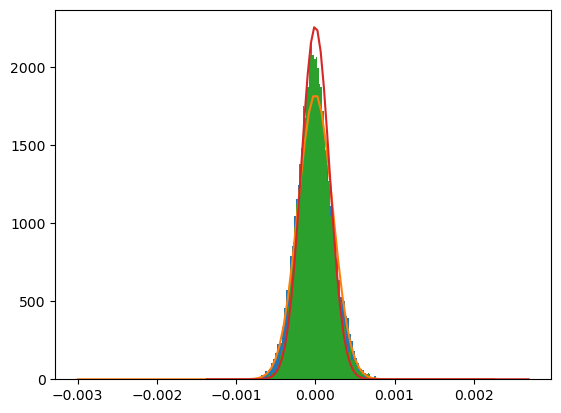

In [31]:
hist1,bins,_=plt.hist(amp1, bins=100, density=True)
bin_centers = (bins[:-1] + bins[1:]) 
plt.plot(bin_centers, norm.pdf(bin_centers, loc=0, scale=torch.sqrt(v1)), label="Analytic PDF")
hist1,bins,_=plt.hist(amp2, bins=100, density=True)
bin_centers = (bins[:-1] + bins[1:]) 
plt.plot(bin_centers, norm.pdf(bin_centers, loc=0, scale=torch.sqrt(v2)), label="Analytic PDF")


## Compute the Background Index

Step 0: J = 0.261732
Step 10: J = 0.261008
Step 20: J = 0.260730
Step 30: J = 0.260551
Step 40: J = 0.260393
Step 50: J = 0.260245
Step 60: J = 0.260101
Step 70: J = 0.259962
Step 80: J = 0.259827
Step 90: J = 0.259697
Final: J = 0.259582
6.893843187717028e-05


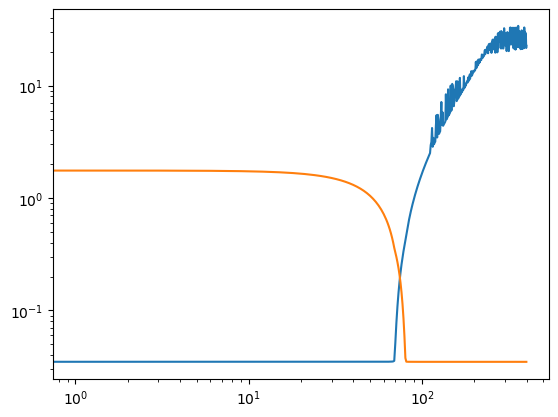

In [109]:
f1_t, f2_t, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, 
                                                       signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma,
                                                        f1_init = f1_t, f2_init = f2_t,
                                                       n_trials=100, use_interp = True, verbose=True)

print(J_values[-1]*fn.K)
plt.loglog(f1_t[:400].detach())
plt.loglog(f2_t[:400].detach())

tensor(6.8788e-05) tensor(0.7410)


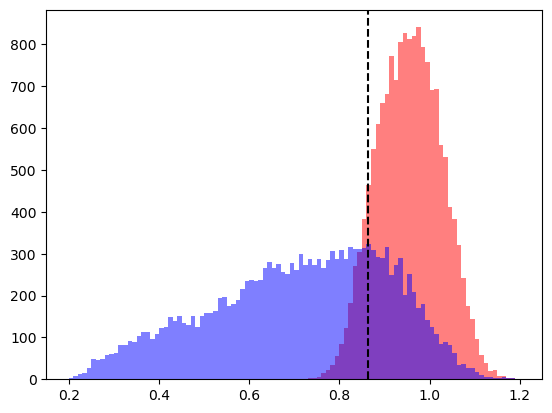

In [110]:
BI, rp, PSD_pileup, PSD_single, Amp_1_pileup, Amp_2_pileup, Amp_1_single, Amp_2_single = an.compute_BI_torch(
            data_pileup,
            data_single,
            acceptance,
            H_unit_torch,
            f1_t,
            f2_t,
            window_fct = np.hanning,
            compute_uncertainty = False,
            batch_size = 2048,
            use_loader = False,
            full_output = True
        )
print(BI, rp)
plt.hist(Amp_1_single/Amp_2_single, bins=100,range=(0.2,1.2), alpha=0.5, label="Single pulse", color="red")
plt.hist(Amp_1_pileup/Amp_2_pileup, bins=100,range=(0.2,1.2), alpha=0.5, label="Pileup pulse", color="blue")
cut = np.percentile(PSD_single,(1-acceptance)*100)
plt.axvline(cut, color="black", linestyle="--", label="Threshold")